### Libaries used for the analysis, Setup and Gatecheck report loaded

In [12]:
import re
import datetime as dt
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 160)

PATH = r"C:\Users\Moses\Downloads\VisitorExcel_2026_9_24_12_47_5_608.xlsx"
raw = pd.read_excel(PATH, sheet_name="reports", header=2)
raw = raw[raw["SNO"].notna()].reset_index(drop=True)
print(f"Loaded {len(raw)} visitor entries")
raw.head()

Loaded 1108 visitor entries


,SNO,Name,Email,Mobile,Person To Meet,Purpose of Meet,Category,Govt ID,Type,Access Card,...,From Address,Persons(+),Vehicle Type,Vehicle No,Parking Slot,TimeIn,TimeOut,Duration,Approved,Issued
0,1,George,orgahemengeorge@gmail.com,09XXXXXX70,Mr. Lawal (First Continental Properties Limit...,Official,Visitor,-,Schedule,NaN,...,Churchgate Tower,1.0,-,-,NaN,05-02-2026 12:34 PM,05-02-2026 12:43 PM,00 : 09 Hrs,Adejoke Abiodun Adepoju,Lawal Muhammed
1,2,Dandy,danielerhabor5@gmail.com,80XXXXXX71,Dandy (GTL Properties Limited),-,NaN,-,Schedule,NaN,...,VI,1.0,-,-,NaN,09-04-2026 12:51 PM,-,-,Adejoke Abiodun Adepoju,Dandy Ovuvu
2,3,Gideon,gadesawe@churchgate.com,81XXXXXX24,Lawal (CHURCHGATE),-,NaN,-,QR Scan,NaN,...,-,1.0,-,-,NaN,05-06-2026 09:43 AM,05-06-2026 09:44 AM,00 : 01 Hrs,Adejoke Abiodun Adepoju,Adejoke Abiodun Adepoju
3,4,George,-,08XXXXXX01,Wale (CHURCHGATE),-,NaN,-,QR Scan,NaN,...,-,1.0,-,-,NaN,05-06-2026 09:53 AM,05-06-2026 11:40 AM,01 : 47 Hrs,Adejoke Abiodun Adepoju,Adejoke Abiodun Adepoju
4,5,Adejoke Adepoju,iyawoekiti2@gmail.com,80XXXXXX01,Magesh Gopal (First Continental Properties Li...,-,NaN,-,QR Scan,NaN,...,-,1.0,-,-,NaN,05-06-2026 10:35 AM,05-06-2026 10:37 AM,00 : 02 Hrs,Adejoke Abiodun Adepoju,Adejoke Abiodun Adepoju


### Cleaned & parsed the Gatecheck dataset

In [13]:
df = raw.copy()

def clean_text(x):
    if pd.isna(x) or str(x).strip() in ("-", "NA", ""):
        return None
    return re.sub(r"\s+", " ", str(x)).strip()

for c in ["Name", "Email", "Person To Meet", "Purpose of Meet", "Category",
          "Type", "Coming From", "From Address", "Approved", "Issued"]:
    df[c] = df[c].apply(clean_text)

# Purpose: normalize casing so "Official " / "Official" / "official" collapse together
df["purpose_clean"] = df["Purpose of Meet"].str.title().fillna("Not Stated")

# Extract the host's company/tenant from "Person To Meet", e.g. "Francis Egba (CHURCHGATE)"
def extract_tenant(x):
    if x is None:
        return None
    m = re.search(r"\(([^)]+)\)", x)
    return m.group(1).strip() if m else None

def extract_host_name(x):
    if x is None:
        return None
    return re.sub(r"\([^)]*\)", "", x).strip()

df["tenant"] = df["Person To Meet"].apply(extract_tenant)
df["host_name"] = df["Person To Meet"].apply(extract_host_name)
# collapse near-duplicate host names: lowercase, strip "mr/ms/mrs"
df["host_name_norm"] = (df["host_name"].str.lower()
                         .str.replace(r"^(mr|ms|mrs|dr)\.?\s+", "", regex=True)
                         .str.strip())

# Parse times
def parse_dt(x):
    if pd.isna(x) or str(x).strip() == "-":
        return pd.NaT
    return pd.to_datetime(x, format="%d-%m-%Y %I:%M %p", errors="coerce")

df["time_in"] = df["TimeIn"].apply(parse_dt)
df["time_out"] = df["TimeOut"].apply(parse_dt)
df["date"] = df["time_in"].dt.date
df["hour_in"] = df["time_in"].dt.hour
df["weekday"] = df["time_in"].dt.day_name()

# Parse Duration ("08 : 14 Hrs" -> 8.23 decimal hours); recompute from timestamps where possible as a cross-check
def parse_duration(x):
    if pd.isna(x) or str(x).strip() == "-":
        return None
    m = re.match(r"(\d+)\s*:\s*(\d+)", str(x))
    if m:
        h, mnt = int(m.group(1)), int(m.group(2))
        return round(h + mnt / 60, 2)
    return None

df["duration_hrs_stated"] = df["Duration"].apply(parse_duration)
df["duration_hrs_computed"] = (df["time_out"] - df["time_in"]).dt.total_seconds() / 3600
df["duration_hrs"] = df["duration_hrs_computed"].fillna(df["duration_hrs_stated"])
df["no_checkout"] = df["time_out"].isna()

print(f"Entries with no recorded checkout: {df['no_checkout'].sum()} ({df['no_checkout'].mean():.0%})")
df[["Name", "tenant", "host_name", "purpose_clean", "time_in", "time_out", "duration_hrs", "no_checkout"]].head(10)

Entries with no recorded checkout: 85 (8%)


,Name,tenant,host_name,purpose_clean,time_in,time_out,duration_hrs,no_checkout
0,George,First Continental Properties Limited,Mr. Lawal,Official,2026-02-05 12:34:00,2026-02-05 12:43:00,0.150000,False
1,Dandy,GTL Properties Limited,Dandy,Not Stated,2026-04-09 12:51:00,NaT,NaN,True
2,Gideon,CHURCHGATE,Lawal,Not Stated,2026-06-05 09:43:00,2026-06-05 09:44:00,0.016667,False
3,George,CHURCHGATE,Wale,Not Stated,2026-06-05 09:53:00,2026-06-05 11:40:00,1.783333,False
4,Adejoke Adepoju,First Continental Properties Limited,Magesh Gopal,Not Stated,2026-06-05 10:35:00,2026-06-05 10:37:00,0.033333,False
5,Adejoke Adepoju,CHURCHGATE,Kayode,Not Stated,2026-06-05 12:10:00,2026-06-05 12:12:00,0.033333,False
6,Oyindamola,CHURCHGATE,MRS JOKE,Not Stated,2026-06-05 12:16:00,2026-06-05 12:17:00,0.016667,False
7,Nonso Osuji,BUCCH ENERGY LIMITED,Mr Bright,Not Stated,2026-06-05 13:12:00,2026-06-05 16:39:00,3.450000,False
8,Adedayo Olufemi,UHURU,Tolu,Official,2026-06-05 13:29:00,2026-06-05 17:19:00,3.833333,False
9,Bejide,WelltecOilfield,Rebecca,Not Stated,2026-06-05 14:20:00,2026-06-05 15:24:00,1.066667,False


### Saved the clean data

In [14]:
df.to_excel("visitor_clean_august2026.xlsx", index=False)
print("Saved visitor_clean_august2026.xlsx")

Saved visitor_clean_august2026.xlsx


### Monthly trend

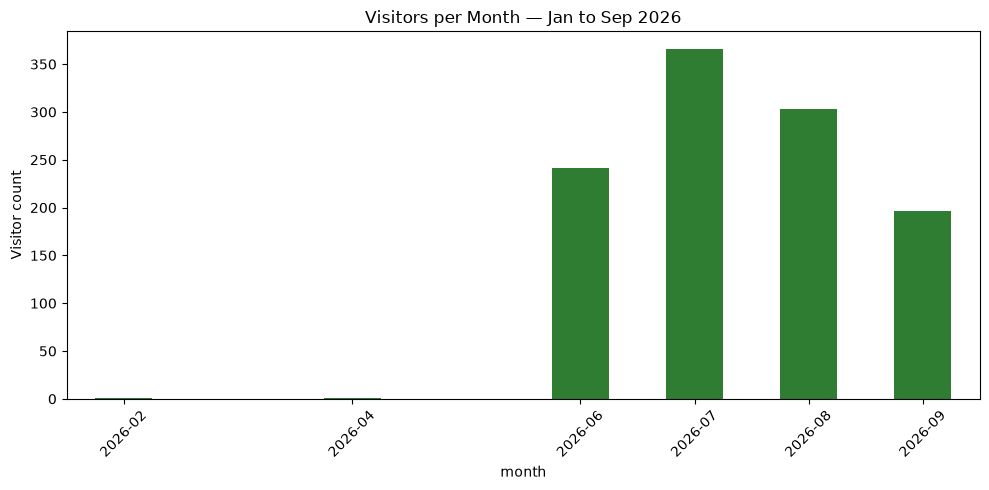

month
2026-02      1
2026-04      1
2026-06    241
2026-07    366
2026-08    303
2026-09    196
Freq: M, dtype: int64


In [15]:
df["month"] = df["time_in"].dt.to_period("M")
monthly = df.groupby("month").size()

fig, ax = plt.subplots(figsize=(10, 5))
monthly.plot(kind="bar", ax=ax, color="#2E7D32")
ax.set_title("Visitors per Month — Jan to Sep 2026")
ax.set_ylabel("Visitor count")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print(monthly)

### Daily & weekday patterns

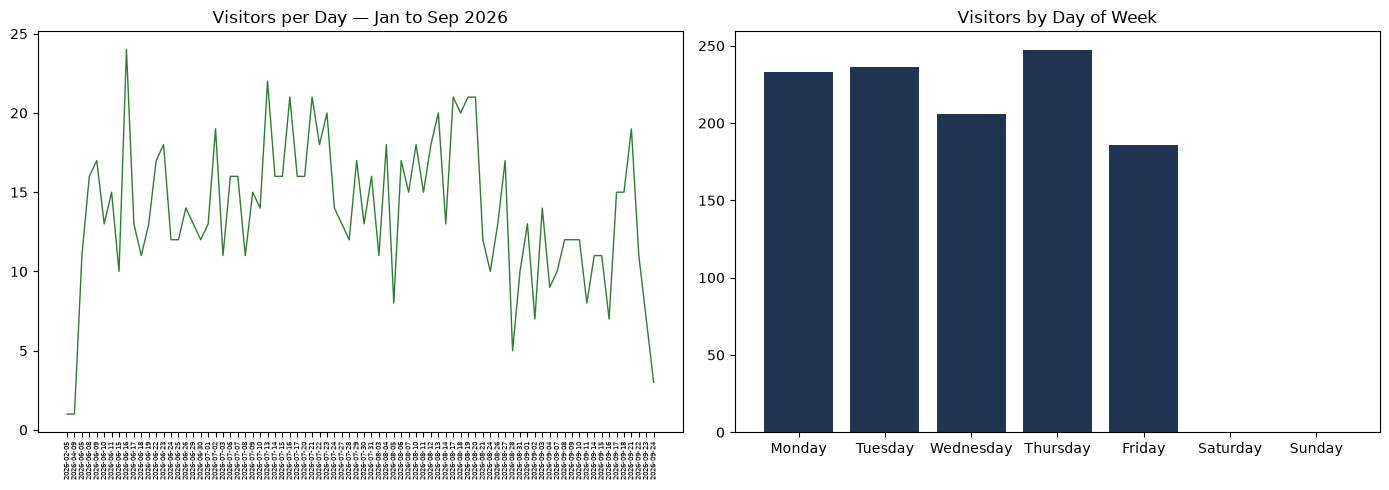

Peak hour of entry:
hour_in
8      38
9     161
10    171
11    158
12    178
13    120
14    122
15     92
16     43
17     25
Name: count, dtype: int64


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

daily = df.groupby("date").size()
axes[0].plot(daily.index.astype(str), daily.values, color="#2E7D32", linewidth=1)
axes[0].set_title("Visitors per Day — Jan to Sep 2026")
axes[0].tick_params(axis="x", rotation=90, labelsize=5)

weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
by_weekday = df["weekday"].value_counts().reindex(weekday_order).fillna(0)
axes[1].bar(by_weekday.index, by_weekday.values, color="#1F3552")
axes[1].set_title("Visitors by Day of Week")
plt.tight_layout()
plt.show()

print("Peak hour of entry:")
print(df["hour_in"].value_counts().sort_index())

### Duration & anomalies

In [17]:
valid_dur = df[df["duration_hrs"].notna()]
print(f"Average visit duration: {valid_dur['duration_hrs'].mean():.2f} hrs")
print(f"Median visit duration: {valid_dur['duration_hrs'].median():.2f} hrs")

long_visits = valid_dur[valid_dur["duration_hrs"] > 6].sort_values("duration_hrs", ascending=False)
print(f"\nVisits longer than 6 hours: {len(long_visits)}")
long_visits[["Name", "tenant", "purpose_clean", "time_in", "duration_hrs"]].head(10)

Average visit duration: 2.44 hrs
Median visit duration: 1.43 hrs

Visits longer than 6 hours: 128


,Name,tenant,purpose_clean,time_in,duration_hrs
488,Victor Fakunwade,CHURCHGATE,Audit,2026-07-22 08:44:00,9.250000
749,Henrienta Akingunsoye,CHURCHGATE,Audit Field Work,2026-08-14 08:36:00,9.183333
162,Jude AjayiKolade,POWERGAS,Official,2026-06-23 08:33:00,9.150000
163,Anthony Antigha,AFRICA PLUS PARTNERS NIGERIA LIMITED,Not Stated,2026-06-23 08:37:00,9.116667
397,Emenike Praise,POWERGAS,Not Stated,2026-07-15 08:49:00,9.033333
396,Jude,POWERGAS,Official,2026-07-15 08:50:00,9.016667
180,Jude,POWERGAS,Official,2026-06-24 08:47:00,8.850000
504,Henrienta Akingunsoye,CHURCHGATE,Audit Field Work,2026-07-23 09:14:00,8.766667
730,Henrienta Akingunsoye,CHURCHGATE,Audit Field Work,2026-08-13 08:55:00,8.750000
729,Victor Fakunwade,CHURCHGATE,Audit,2026-08-13 08:52:00,8.750000


In [18]:
print("Visitors with NO recorded checkout (security/data gap):")
df[df["no_checkout"]][["Name", "tenant", "host_name", "time_in", "purpose_clean"]]

Visitors with NO recorded checkout (security/data gap):


,Name,tenant,host_name,time_in,purpose_clean
1,Dandy,GTL Properties Limited,Dandy,2026-04-09 12:51:00,Not Stated
27,Judith,BUCCH ENERGY LIMITED,Mr Bright,2026-06-08 15:58:00,Meeting
28,Nsikak,Greenwich Capital Limited,Gbemisola,2026-06-08 17:34:00,Not Stated
41,Olamide,03Capital Nigeria Limited,David,2026-06-09 15:15:00,Work
58,Olumuyiwa Olusanya,Greenwich Capital Limited,Mr Kayode Falowo,2026-06-10 17:11:00,Official
...,...,...,...,...,...
782,Olanrewaju,CHURCHGATE,Mr. Bora,2026-08-17 17:24:00,Personal
803,Victor Fakunwade,CHURCHGATE,Mr olaife,2026-08-19 08:51:00,Audit
804,Henrienta Akingunsoye,CHURCHGATE,Mr Olaife,2026-08-19 08:50:00,Audit Field Work
809,Mosunmola Ajayi,CHURCHGATE,Mr Olaife,2026-08-19 10:02:00,Audit


### Tenant / host load

Visitors by tenant/company:
tenant
CHURCHGATE                              197
POWERGAS                                172
AFRICA PLUS PARTNERS NIGERIA LIMITED    148
03Capital Nigeria Limited               117
Greenwich Capital Limited               108
BUCCH ENERGY LIMITED                     82
Greenwich Holdings Limited               73
First Continental Properties Limited     71
UHURU                                    45
BlueBerryTravel                          42
GTL Properties Limited                   20
MaxHealth                                11
WelltecOilfield                          10
Greenwich Merchant Bank                   6
Carolina Logistics                        4
MD                                        1
EMIRATE AIRLINES                          1
Name: count, dtype: int64


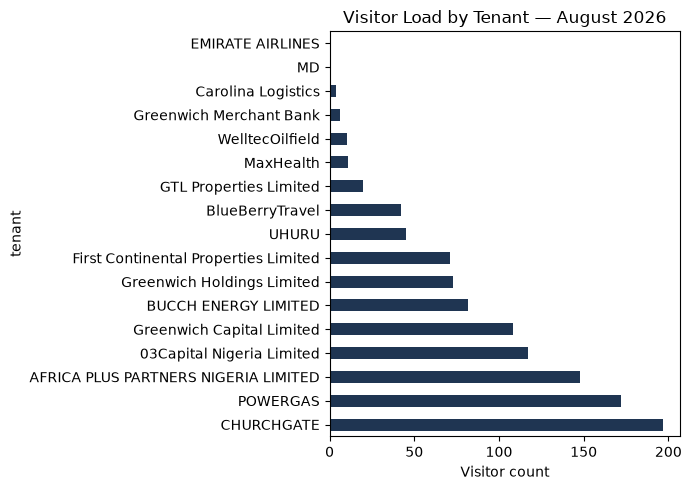


Top hosts by visitor count (name-normalized):
host_name_norm
samson ogundimu    37
finance            34
bright             33
samson             33
olaife             31
gbemisola          21
francis            18
niran              18
chisom             18
dandy              17
Name: count, dtype: int64


In [19]:
tenant_counts = df["tenant"].value_counts()
print("Visitors by tenant/company:")
print(tenant_counts)

fig, ax = plt.subplots(figsize=(7, 5))
tenant_counts.plot(kind="barh", ax=ax, color="#1F3552")
ax.set_xlabel("Visitor count")
ax.set_title("Visitor Load by Tenant — August 2026")
plt.tight_layout()
plt.show()

print("\nTop hosts by visitor count (name-normalized):")
print(df["host_name_norm"].value_counts().head(10))

### Purpose of visit

purpose_clean
Not Stated           349
Official             304
Meeting              100
Audit                 83
Interview             26
                    ... 
Dropping A Letter      1
Pick Up Car Keys       1
Direct Meeting M       1
Health Session         1
Re                     1
Name: count, Length: 153, dtype: int64


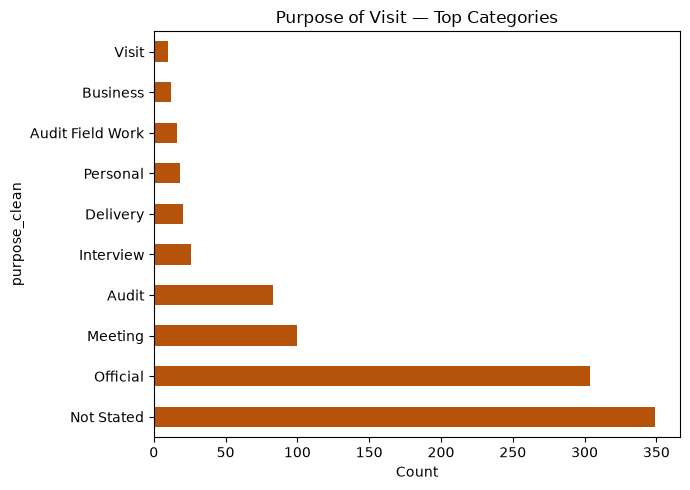

In [20]:
purpose_counts = df["purpose_clean"].value_counts()
print(purpose_counts)

fig, ax = plt.subplots(figsize=(7, 5))
purpose_counts.head(10).plot(kind="barh", ax=ax, color="#B45309")
ax.set_xlabel("Count")
ax.set_title("Purpose of Visit — Top Categories")
plt.tight_layout()
plt.show()

### Compliance & process gaps

In [21]:
total = len(df)
print(f"Total visitors: {total}")
print(f"Missing email: {df['Email'].isna().sum()} ({df['Email'].isna().mean():.0%})")
print(f"Missing Govt ID: {(df['Govt ID'].isna()).sum()} ({(df['Govt ID'].isna()).mean():.0%})")
print(f"No checkout recorded: {df['no_checkout'].sum()} ({df['no_checkout'].mean():.0%})")
print()
print("Entry type breakdown:")
print(df["Type"].value_counts())
print()
print("Unique approvers:")
print(df["Approved"].value_counts())

Total visitors: 1108
Missing email: 521 (47%)
Missing Govt ID: 0 (0%)
No checkout recorded: 85 (8%)

Entry type breakdown:
Type
QR Scan     802
Walk-in     299
Schedule      7
Name: count, dtype: int64

Unique approvers:
Approved
Adejoke Abiodun Adepoju    1108
Name: count, dtype: int64


### Chart: entry type + approver concentration

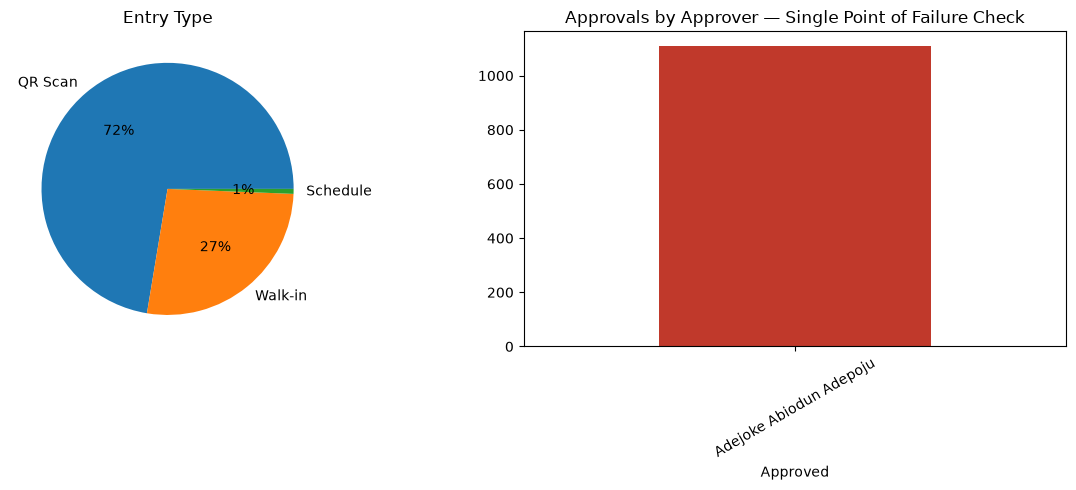

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
df["Type"].value_counts().plot(kind="pie", ax=axes[0], autopct="%1.0f%%", ylabel="")
axes[0].set_title("Entry Type")

df["Approved"].value_counts().plot(kind="bar", ax=axes[1], color="#c0392b")
axes[1].set_title("Approvals by Approver — Single Point of Failure Check")
axes[1].tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()